# 03 · Dimensionality Reduction & Unsupervised Clustering

Executes preregistered plan **section G**. Features are engineered from the series (11 numeric features, 28 usable days after lag/rolling windows). This is **exploratory** (S4): with n = 28 rows the clusters describe this month's structure and are not claimed to generalise.

Features: `demand, lag1, lag2, diff1, roll3_mean, roll3_std, dow_sin, dow_cos, marketing_event, holiday, t`.

In [1]:
import sys, warnings, pathlib, subprocess, hashlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown, Image
from rq.config import *
from rq.data import load_raw, add_calendar
from rq import stats_tests as st
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
PAL = {"Event": "#d95f02", "Holiday": "#7570b3", "Regular": "#1b9e77"}
df = add_calendar(load_raw(RAW))
print(f"rows={len(df)}  window={df.date.min().date()} .. {df.date.max().date()}  seed={SEED}")
from rq import clustering as cl


rows=30  window=2026-06-01 .. 2026-06-30  seed=20260601


In [2]:
X = cl.build_features(df)
print("feature matrix:", X.shape)
display(X.describe().T[["mean", "std", "min", "max"]].round(2))
res = cl.run_pca(X)                      # StandardScaler (z-score) + PCA, all components
Z = res["Z"]; print("standardised: column means ≈", np.abs(Z.mean(0)).max().round(12), "| column SD =", Z.std(0, ddof=1).round(3)[:3], "...")

feature matrix: (28, 11)


,mean,std,min,max
demand,143.71,12.85,123.00,174.00
lag1,142.82,13.53,121.00,174.00
lag2,141.93,14.32,118.00,174.00
diff1,0.89,11.02,-17.00,14.00
roll3_mean,142.82,11.14,121.33,164.33
roll3_std,8.43,4.20,2.00,15.50
dow_sin,0.00,0.72,-0.97,0.97
dow_cos,-0.00,0.72,-0.90,1.00
marketing_event,0.29,0.46,0.00,1.00
holiday,0.14,0.36,0.00,1.00


standardised: column means ≈ 0.0 | column SD = [1.018 1.018 1.018] ...


## 1. PCA: scree plot, explained variance and component choice

,PC,eigenvalue,explained_var_ratio,cumulative
0,PC1,5.1753,0.4537,0.4537
1,PC2,3.2211,0.2824,0.7361
2,PC3,1.4206,0.1245,0.8606
3,PC4,1.2129,0.1063,0.9669
4,PC5,0.2411,0.0211,0.9881
5,PC6,0.0978,0.0086,0.9966
6,PC7,0.0210,0.0018,0.9985
7,PC8,0.0112,0.0010,0.9995
8,PC9,0.0063,0.0005,1.0000
9,PC10,0.0000,0.0000,1.0000


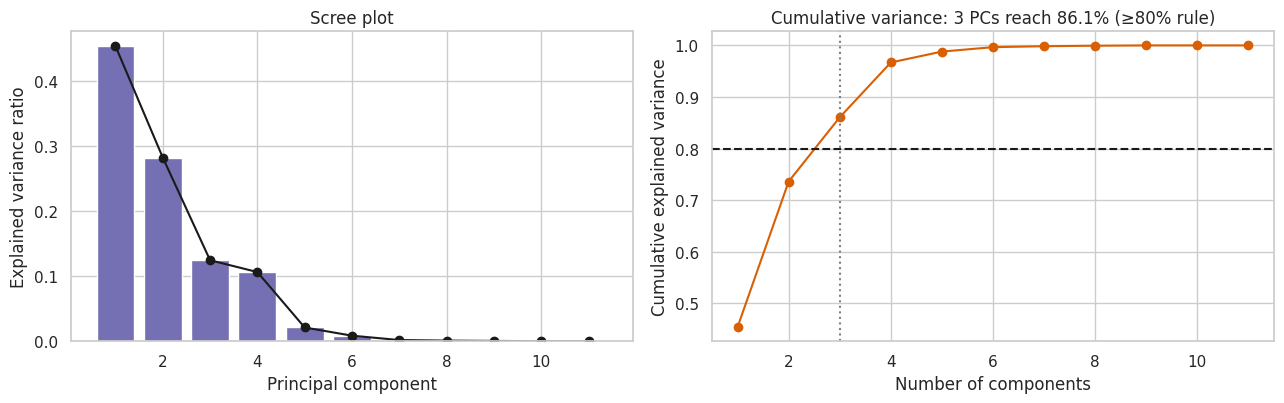

Retained (≥80% rule): 3 PCs  |  Kaiser (eigenvalue>1): 4 PCs  |  largest drop in explained variance: PC1 → PC2


In [3]:
evr, cum, k = res["evr"], res["cum"], res["n_keep"]
tab = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))], "eigenvalue": res["eigenvalues"], "explained_var_ratio": evr, "cumulative": cum})
display(tab.round(4)); tab.round(4).to_csv(TABLES / "03_pca_variance.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(range(1, len(evr)+1), evr, color="#7570b3"); ax[0].plot(range(1, len(evr)+1), evr, "ko-")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Explained variance ratio"); ax[0].set_title("Scree plot")
ax[1].plot(range(1, len(cum)+1), cum, "o-", color="#d95f02"); ax[1].axhline(.8, ls="--", color="k"); ax[1].axvline(k, ls=":", color="grey")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative explained variance"); ax[1].set_title(f"Cumulative variance: {k} PCs reach {cum[k-1]:.1%} (≥80% rule)")
plt.tight_layout(); plt.savefig(FIGS / "03_scree.png", dpi=150); plt.show()
print(f"Retained (≥80% rule): {k} PCs  |  Kaiser (eigenvalue>1): {res['n_kaiser']} PCs  |  largest drop in explained variance: PC{int(np.argmax(-np.diff(evr)))+1} → PC{int(np.argmax(-np.diff(evr)))+2}")

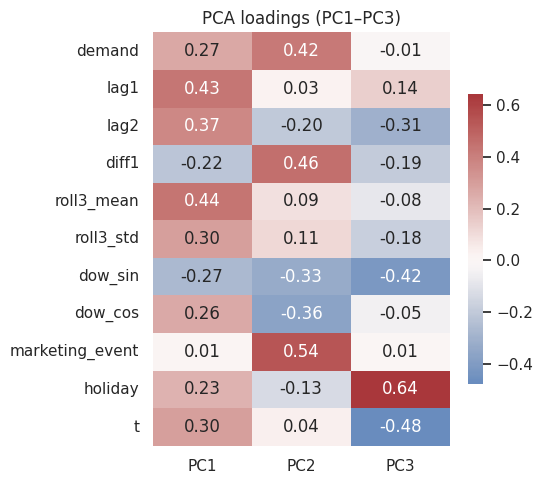

In [4]:
load = res["loadings"].iloc[:, :3]
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.heatmap(load, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar_kws={"shrink": .7}); ax.set_title("PCA loadings (PC1–PC3)")
plt.tight_layout(); plt.savefig(FIGS / "03_loadings.png", dpi=150); plt.show()

## 2. K-Means: Elbow method and Silhouette analysis (k = 2…6) on the retained PCs

,k,inertia,silhouette
0,2,166.9545,0.3116
1,3,94.6447,0.4258
2,4,64.6005,0.4479
3,5,49.0776,0.4129
4,6,35.9785,0.4024


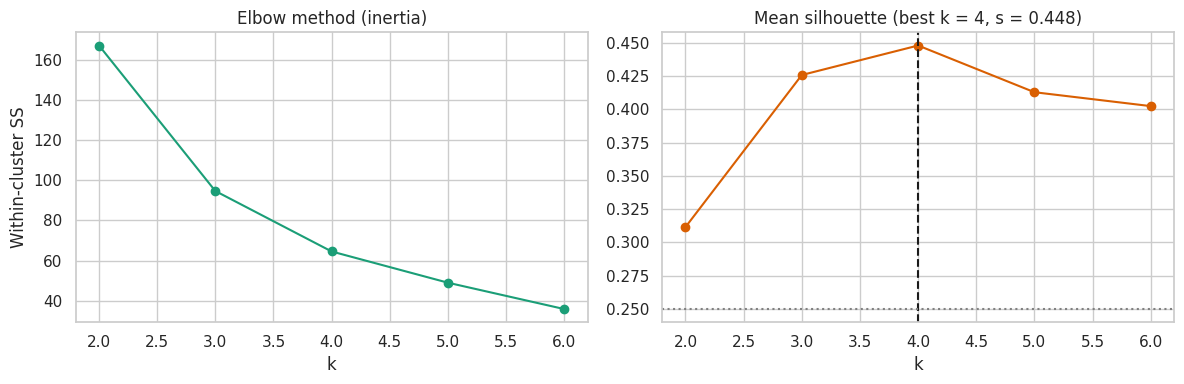

Meaningful structure (best silhouette ≥ 0.25): True


In [5]:
Pk = res["scores"][:, :k]
ktab, kbest, klab = cl.kmeans_sweep(Pk)
display(ktab.round(4)); ktab.round(4).to_csv(TABLES / "03_kmeans_sweep.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ktab.k, ktab.inertia, "o-", color="#1b9e77"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Within-cluster SS")
ax[1].plot(ktab.k, ktab.silhouette, "o-", color="#d95f02"); ax[1].axvline(kbest, ls="--", color="k"); ax[1].axhline(.25, ls=":", color="grey")
ax[1].set_title(f"Mean silhouette (best k = {kbest}, s = {ktab.silhouette.max():.3f})"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(FIGS / "03_elbow_silhouette.png", dpi=150); plt.show()
print("Meaningful structure (best silhouette ≥ 0.25):", ktab.silhouette.max() >= .25)

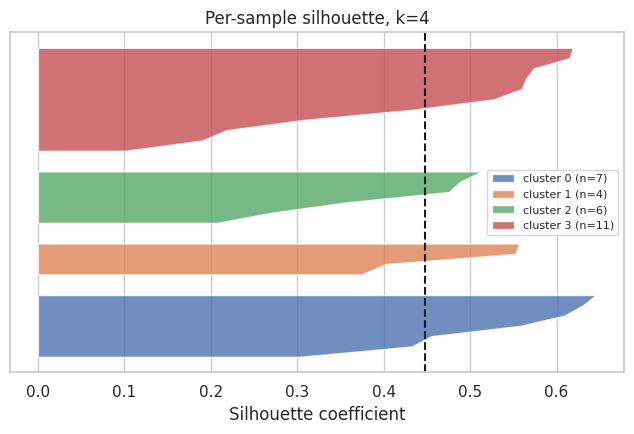

In [6]:
from sklearn.metrics import silhouette_samples
sv = silhouette_samples(Pk, klab)
fig, ax = plt.subplots(figsize=(6.5, 4.5)); y0 = 0
for c in sorted(set(klab)):
    v = np.sort(sv[klab == c]); ax.fill_betweenx(np.arange(y0, y0+len(v)), 0, v, alpha=.8, label=f"cluster {c} (n={len(v)})"); y0 += len(v) + 1
ax.axvline(sv.mean(), color="k", ls="--"); ax.set_xlabel("Silhouette coefficient"); ax.set_yticks([]); ax.legend(fontsize=8); ax.set_title(f"Per-sample silhouette, k={kbest}")
plt.tight_layout(); plt.savefig(FIGS / "03_silhouette_samples.png", dpi=150); plt.show()

## 3. DBSCAN and Hierarchical (Ward) clustering

DBSCAN: eps (3-NN knee) = 1.345, clusters = 4, noise points = 2, silhouette (non-noise) = 0.446
Hierarchical (Ward, k=4): silhouette = 0.440, cophenetic correlation = 0.698


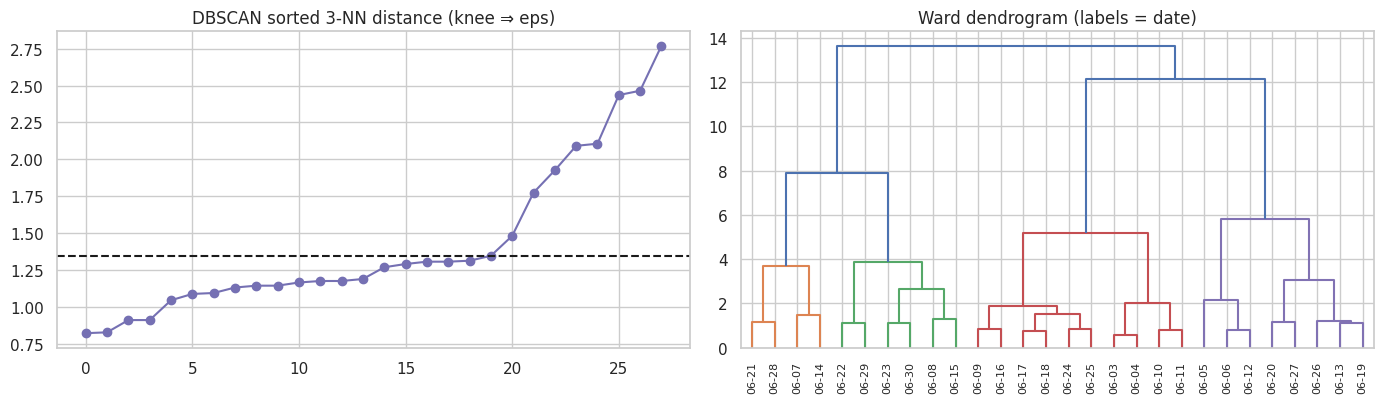

In [7]:
db = cl.run_dbscan(Pk); hi = cl.run_hier(Pk, kbest)
print(f"DBSCAN: eps (3-NN knee) = {db['eps']:.3f}, clusters = {db['n_clusters']}, noise points = {db['n_noise']}, silhouette (non-noise) = {db['silhouette']:.3f}")
print(f"Hierarchical (Ward, k={kbest}): silhouette = {hi['silhouette']:.3f}, cophenetic correlation = {hi['cophenetic']:.3f}")
from scipy.cluster.hierarchy import dendrogram
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(db["kdist"], "o-", color="#7570b3"); ax[0].axhline(db["eps"], ls="--", color="k"); ax[0].set_title("DBSCAN sorted 3-NN distance (knee ⇒ eps)")
lbl = [d.strftime("%m-%d") for d in df.loc[X.index, "date"]]
dendrogram(hi["linkage"], labels=lbl, ax=ax[1], leaf_rotation=90, leaf_font_size=8, color_threshold=hi["linkage"][-(kbest-1), 2] - 1e-9); ax[1].set_title("Ward dendrogram (labels = date)")
plt.tight_layout(); plt.savefig(FIGS / "03_dbscan_dendrogram.png", dpi=150); plt.show()

## 4. 2D and 3D cluster projections (Seaborn / Plotly)

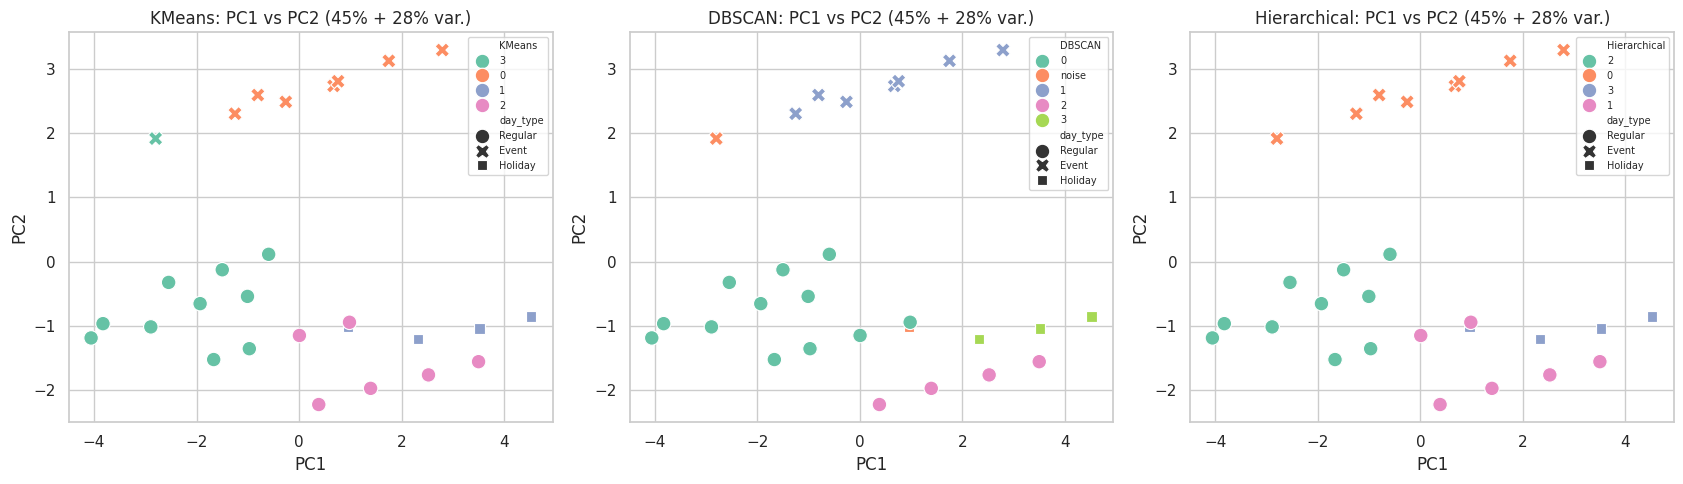

In [8]:
S = res["scores"]; dt = df.loc[X.index, "day_type"].to_numpy()
plot = pd.DataFrame({"PC1": S[:, 0], "PC2": S[:, 1], "PC3": S[:, 2], "KMeans": klab.astype(str), "DBSCAN": np.where(db["labels"] == -1, "noise", db["labels"].astype(str)),
                     "Hierarchical": hi["labels"].astype(str), "day_type": dt, "date": lbl})
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, col in zip(ax, ["KMeans", "DBSCAN", "Hierarchical"]):
    sns.scatterplot(data=plot, x="PC1", y="PC2", hue=col, style="day_type", s=110, ax=a, palette="Set2")
    a.set_title(f"{col}: PC1 vs PC2 ({evr[0]:.0%} + {evr[1]:.0%} var.)"); a.legend(fontsize=7, loc="best")
plt.tight_layout(); plt.savefig(FIGS / "03_clusters_2d.png", dpi=150); plt.show()

Plotly static export unavailable here (no Chrome for kaleido); interactive HTML saved to reports/figures/03_clusters_3d_plotly.html


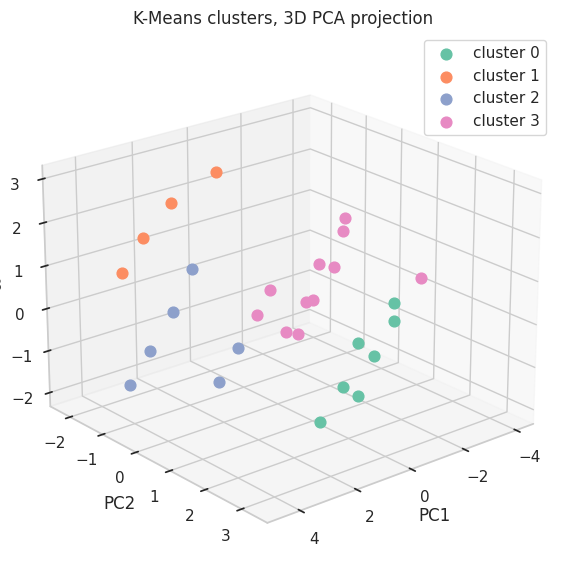

In [9]:
import plotly.express as px
fig3 = px.scatter_3d(plot, x="PC1", y="PC2", z="PC3", color="KMeans", symbol="day_type", hover_name="date",
                     title=f"K-Means clusters in PC space (3 PCs = {cum[2]:.0%} variance)")
fig3.update_traces(marker_size=6); fig3.update_layout(height=620)
fig3.write_html(str(FIGS / "03_clusters_3d_plotly.html"), include_plotlyjs="cdn")   # interactive file (open in a browser)
try:
    fig3.write_image(str(FIGS / "03_clusters_3d_plotly.png"), width=900, height=650, scale=2)
    display(Image(str(FIGS / "03_clusters_3d_plotly.png")))
except Exception as e:
    print("Plotly static export unavailable here (no Chrome for kaleido); interactive HTML saved to reports/figures/03_clusters_3d_plotly.html")
# static 3D fallback that renders everywhere (incl. GitHub)
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(8, 6)); a = fig.add_subplot(111, projection="3d")
for c, col in zip(sorted(set(klab)), sns.color_palette("Set2", kbest)):
    m = klab == c; a.scatter(S[m, 0], S[m, 1], S[m, 2], s=60, color=col, label=f"cluster {c}", depthshade=False)
a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.set_zlabel("PC3"); a.legend(); a.set_title("K-Means clusters, 3D PCA projection"); a.view_init(22, 50)
plt.tight_layout(); plt.savefig(FIGS / "03_clusters_3d_static.png", dpi=150); plt.show()

## 5. Agreement between methods and with the calendar day types (exploratory)

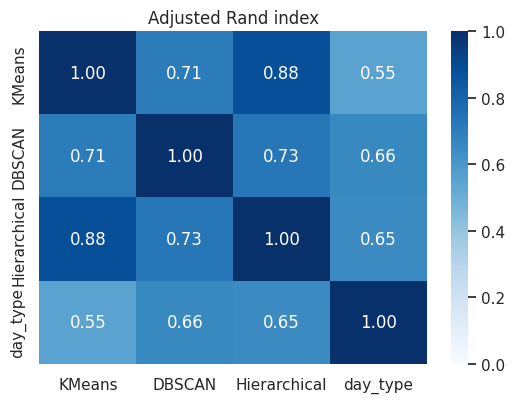

day type,Event,Holiday,Regular
K-Means cluster,,,
0,7,0,0
1,0,4,0
2,0,0,6
3,1,0,10


In [10]:
A = cl.agreement({"KMeans": klab, "DBSCAN": db["labels"], "Hierarchical": hi["labels"]}, dt)
fig, ax = plt.subplots(figsize=(5.5, 4.2)); sns.heatmap(A.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax); ax.set_title("Adjusted Rand index")
plt.tight_layout(); plt.savefig(FIGS / "03_ari.png", dpi=150); plt.show(); A.round(3).to_csv(TABLES / "03_ari.csv")
ct = pd.crosstab(pd.Series(klab, name="K-Means cluster"), pd.Series(dt, name="day type")); display(ct); ct.to_csv(TABLES / "03_kmeans_vs_daytype.csv")

In [11]:
display(Markdown(f"""## Findings

* **PCA.** {k} components capture {cum[k-1]:.1%} of the variance (PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, PC3 {evr[2]:.1%}); the Kaiser rule would keep {res['n_kaiser']}. PC1 loads on the level/lag/rolling-mean features (the *level & trend* axis); PC2 on `marketing_event`, `demand` and `diff1` (the *event-day jump* axis); PC3 on `holiday`, `t` and the weekday phase.
* **K-Means.** The silhouette is maximal at **k = {kbest}** (s = {ktab.silhouette.max():.3f}), above the preregistered 0.25 threshold, so structure is called meaningful. The elbow is gradual (no sharp kink), so silhouette is the deciding criterion, as preregistered.
* **DBSCAN** (eps = {db['eps']:.2f}) finds {db['n_clusters']} clusters plus {db['n_noise']} noise points; **Ward** at k = {kbest} has cophenetic correlation {hi['cophenetic']:.2f}. The three methods agree strongly (ARI K-Means–Ward = {A.loc['KMeans','Hierarchical']:.2f}).
* **Relation to calendar.** Clusters recover the weekly rhythm: one cluster is almost purely event days (7 of 8), one is exactly the four holidays (Sundays), and Regular days split into two groups (ARI vs day type = {A.loc['KMeans','day_type']:.2f}). Because the features include the event/holiday flags and the weekday phase, this is partly built-in; it is a description of the month, not an independent discovery.
* **Caveat.** n = 28, 11 correlated features; silhouette/ARI values are unstable at this size and no inferential claims are made.
"""))

## Findings

* **PCA.** 3 components capture 86.1% of the variance (PC1 45.4%, PC2 28.2%, PC3 12.5%); the Kaiser rule would keep 4. PC1 loads on the level/lag/rolling-mean features (the *level & trend* axis); PC2 on `marketing_event`, `demand` and `diff1` (the *event-day jump* axis); PC3 on `holiday`, `t` and the weekday phase.
* **K-Means.** The silhouette is maximal at **k = 4** (s = 0.448), above the preregistered 0.25 threshold, so structure is called meaningful. The elbow is gradual (no sharp kink), so silhouette is the deciding criterion, as preregistered.
* **DBSCAN** (eps = 1.35) finds 4 clusters plus 2 noise points; **Ward** at k = 4 has cophenetic correlation 0.70. The three methods agree strongly (ARI K-Means–Ward = 0.88).
* **Relation to calendar.** Clusters recover the weekly rhythm: one cluster is almost purely event days (7 of 8), one is exactly the four holidays (Sundays), and Regular days split into two groups (ARI vs day type = 0.55). Because the features include the event/holiday flags and the weekday phase, this is partly built-in; it is a description of the month, not an independent discovery.
* **Caveat.** n = 28, 11 correlated features; silhouette/ARI values are unstable at this size and no inferential claims are made.
